# Proyecto Final · Entrega 3: Modelo Predictivo (Business Analytics)
**Caso de negocio:** BPO Alfa Colombia — Proceso de Liquidación de Retiros y Devolución de Activos  
**Equipo:** Angie Natali Sánchez Muñoz (`507232753`) · Juana Valentina Sotomayor Niño (`507232708`)  
**Docente:** Leandro Pájaro Fuentes  

---

## 1. Comprensión del Negocio y Definición del Problema Analítico
- **Pregunta BA (`P5`):** *¿Qué casos de retiro reportados requerirán un reproceso de **reliquidación** (`CasoConReliquidacion_0_1 = 1`) según las condiciones operativas del contrato (transportadora asignada, compañía, motivo de retiro), la ubicación geográfica, el comportamiento histórico de la sede/transportadora en el mes anterior y el registro de descuentos por activos?*
- **Decisión que apoya:** Priorizar preventivamente el seguimiento logístico y el contacto del equipo de Paz y Salvos desde la etapa inicial del retiro en los contratos con alta probabilidad de reliquidación, reduciendo el reproceso financiero y administrativo de reliquidar contratos cerrados.
- **Variable Objetivo:** `CasoConReliquidacion_0_1` (`1` = Requiere reliquidación; `0` = Cierre normal sin reliquidación).
- **Tipo de problema:** Clasificación binaria supervisada.
- **Criterio de éxito:** En el conjunto de prueba temporal (junio a octubre de 2026), alcanzar una **Sensibilidad (Recall) $\ge 85\%$** en la clase positiva (detectar al menos 85 de cada 100 casos que realmente requieren reliquidación) y una **Exactitud global (Accuracy) $\ge 90\%$**.

In [1]:
import os
import json
import urllib.parse
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report
)

os.makedirs("figuras", exist_ok=True)
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 9.5
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Comprensión de los Datos y Extracción desde el Data Warehouse (`bi_entrega2`)
Se ejecuta la consulta [`extraccion.sql`](./extraccion.sql) directamente sobre el Data Warehouse `bi_entrega2` en MySQL mediante `SQLAlchemy`, integrando `fac_retiro` con `dim_tiempo`, `dim_ubicacion`, `dim_contrato` y `dim_estado`.

In [2]:
# Configuración de conexión al Data Warehouse (usa variables de entorno con valores por defecto locales)
db_user = os.getenv("DB_USER", "bi_entrega2_user")
db_pass = os.getenv("DB_PASS", "bi_IN507232753")
db_host = os.getenv("DB_HOST", "localhost")
db_port = os.getenv("DB_PORT", "3306")
db_name = os.getenv("DB_NAME", "bi_entrega2")

conn_str = f"mysql+pymysql://{db_user}:{urllib.parse.quote_plus(db_pass)}@{db_host}:{db_port}/{db_name}?charset=utf8mb4"
engine = create_engine(conn_str)

sql_path = "extraccion.sql" if os.path.exists("extraccion.sql") else os.path.join("modelo", "extraccion.sql")
with open(sql_path, "r", encoding="utf-8") as f:
    sql_query = f.read()

df = pd.read_sql(sql_query, engine)
print(f"Total de registros extraídos del DW: {len(df):,}")
print(f"Periodo cubierto: {df['FechaReporte'].min()} hasta {df['FechaReporte'].max()}")
print(f"Total de columnas extraídas: {df.shape[1]}")
df.head(5)

Total de registros extraídos del DW: 64,674
Periodo cubierto: 2024-10-14 hasta 2026-10-15
Total de columnas extraídas: 32


,CasoKey,ContratoKey,UbicacionKey,EstadoKey,FechaReporteKey,FechaReporte,AnioReporte,TrimestreReporte,MesReporte,NombreMesReporte,...,Transportadora,CECO,EstadoDevolucion,EstadoLiquidacion,DiasReporteLiquidacion,LiquidadoEn10Dias_0_1,CantidadActivosPendientes,CasoConDescuento_0_1,ValorDescontadoCOP,CasoConReliquidacion_0_1
0,42931,3,1,1,20241014,2024-10-14,2024,4,10,Octubre,...,Sin Asignaciones,-,SIN ACTIVOS,Liquidado,1.0,1,0,0,0.0,0
1,16184,4,1,1,20241015,2024-10-15,2024,4,10,Octubre,...,Coordinadora,CC-6163,SIN ACTIVOS,Liquidado,2.0,1,0,0,0.0,0
2,39904,2,126,1,20241015,2024-10-15,2024,4,10,Octubre,...,Sin Asignaciones,-,SIN ACTIVOS,Liquidado,6.0,1,0,0,0.0,0
3,13275,6,1,1,20241016,2024-10-16,2024,4,10,Octubre,...,Sin Asignaciones,-,SIN ACTIVOS,Liquidado,3.0,1,0,0,0.0,0
4,15124,12,1,1,20241017,2024-10-17,2024,4,10,Octubre,...,Sin Asignaciones,-,SIN ACTIVOS,Liquidado,14.0,0,0,0,0.0,0


### 2.3 Distribución de la Variable Objetivo (`CasoConReliquidacion_0_1` — Figura 1)

,Casos,Proporcion_%
CasoConReliquidacion_0_1,,
0,51999,80.4
1,12675,19.6


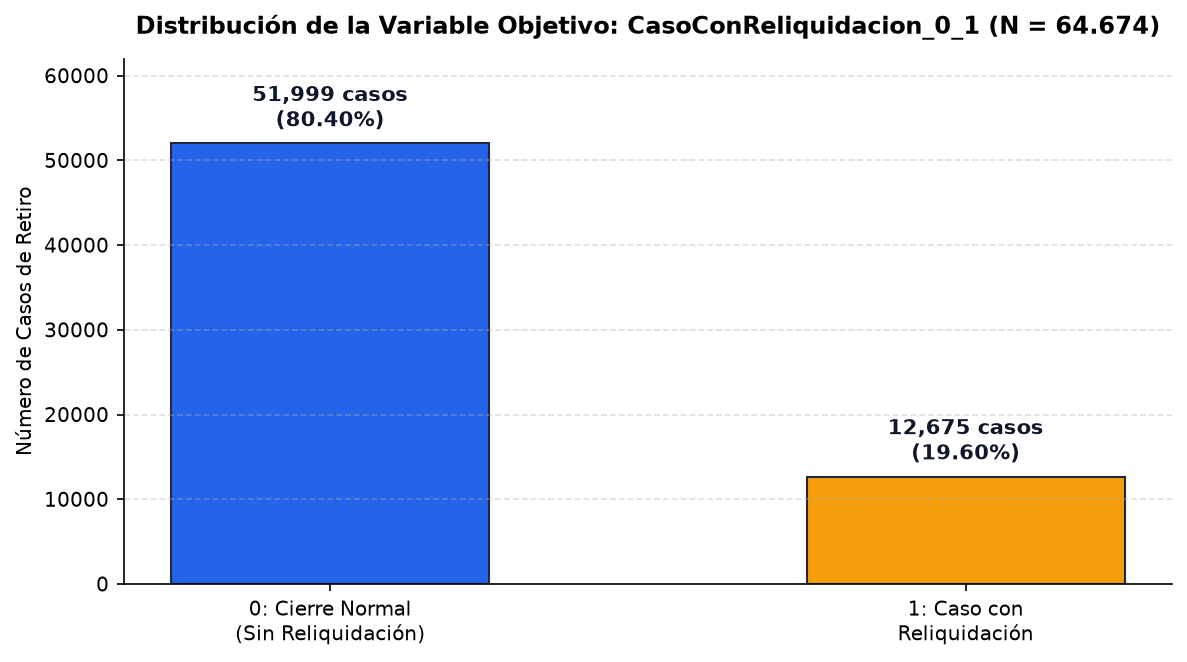

In [3]:
# Figura 1: Distribución de clases de la variable objetivo CasoConReliquidacion_0_1
dist_obj = df["CasoConReliquidacion_0_1"].value_counts().sort_index().rename("Casos").to_frame()
dist_obj["Proporcion_%"] = (dist_obj["Casos"] / len(df) * 100).round(2)
display(dist_obj)

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)
counts = df["CasoConReliquidacion_0_1"].value_counts().sort_index()
pcts = counts / len(df) * 100
labels = ["0: Cierre Normal\n(Sin Reliquidación)", "1: Caso con\nReliquidación"]
colors = ["#2563EB", "#F59E0B"]
bars = ax.bar(labels, counts.values, color=colors, width=0.5, edgecolor="#1E293B", linewidth=1)
for bar, c, p in zip(bars, counts.values, pcts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1200,
            f"{c:,} casos\n({p:.2f}%)", ha="center", va="bottom", fontweight="bold", fontsize=10, color="#0F172A")
ax.set_ylim(0, 62000)
ax.set_ylabel("Número de Casos de Retiro")
ax.set_title("Distribución de la Variable Objetivo: CasoConReliquidacion_0_1 (N = 64.674)", fontweight="bold", pad=12)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig("figuras/fig1_distribucion_objetivo.png", dpi=180)
plt.show()

### 2.4 Análisis Exploratorio de Datos (EDA — Figuras 2, 3, 4 y 5)
A continuación se generan los 4 gráficos exploratorios incluidos en el informe (`Figura 2` a `Figura 5`), cruzando las variables de entrada con la variable objetivo `CasoConReliquidacion_0_1`:

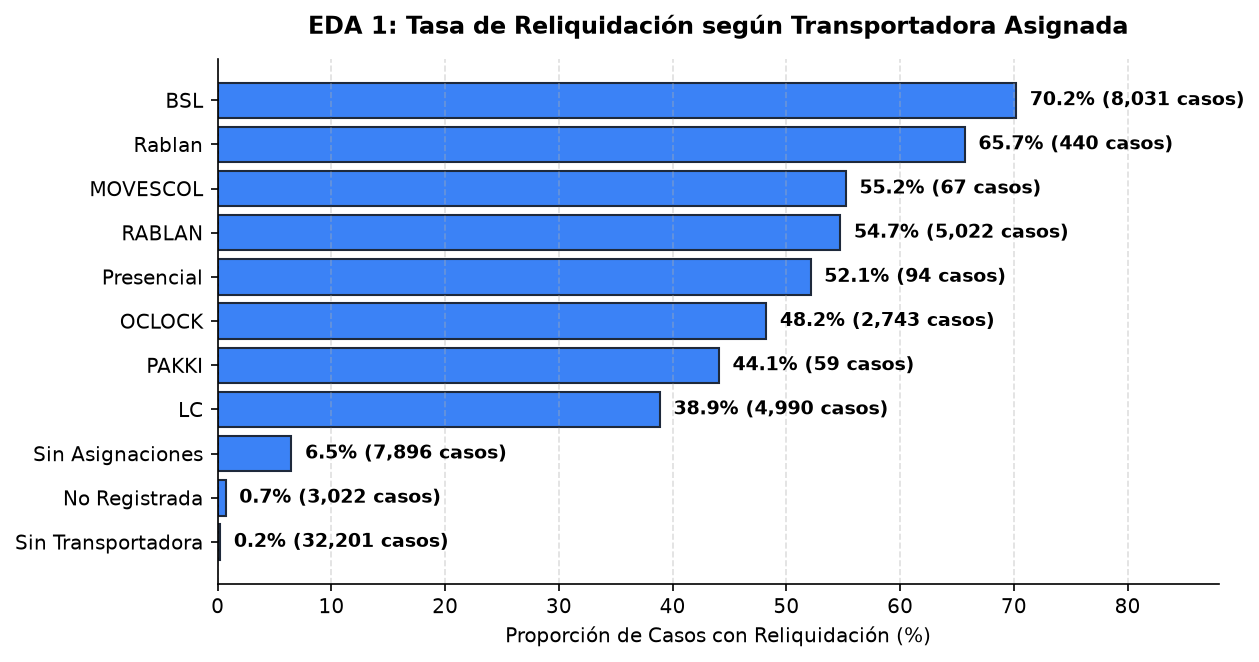

In [4]:
# Figura 2 (EDA 1): Tasa de Reliquidación según Transportadora Asignada
df["Transportadora_Limpia"] = df["Transportadora"].replace({"-": "Sin Transportadora", "NULL": "No Registrada"}).fillna("No Registrada")

fig, ax = plt.subplots(figsize=(8.5, 4.5), dpi=150)
top_tr = df.groupby("Transportadora_Limpia").agg(
    casos=("CasoKey", "count"),
    tasa=("CasoConReliquidacion_0_1", lambda x: x.mean()*100)
).reset_index()
top_tr = top_tr[top_tr["casos"] >= 50].sort_values("tasa", ascending=True)
bars = ax.barh(top_tr["Transportadora_Limpia"], top_tr["tasa"], color="#3B82F6", edgecolor="#1E293B")
for bar, (_, row) in zip(bars, top_tr.iterrows()):
    ax.text(bar.get_width() + 1.2, bar.get_y() + bar.get_height()/2,
            f"{row['tasa']:.1f}% ({int(row['casos']):,} casos)", va="center", fontsize=9, fontweight="bold")
ax.set_xlim(0, 88)
ax.set_xlabel("Proporción de Casos con Reliquidación (%)")
ax.set_title("EDA 1: Tasa de Reliquidación según Transportadora Asignada", fontweight="bold", pad=12)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig("figuras/fig2_eda_transportadora.png", dpi=180)
plt.show()

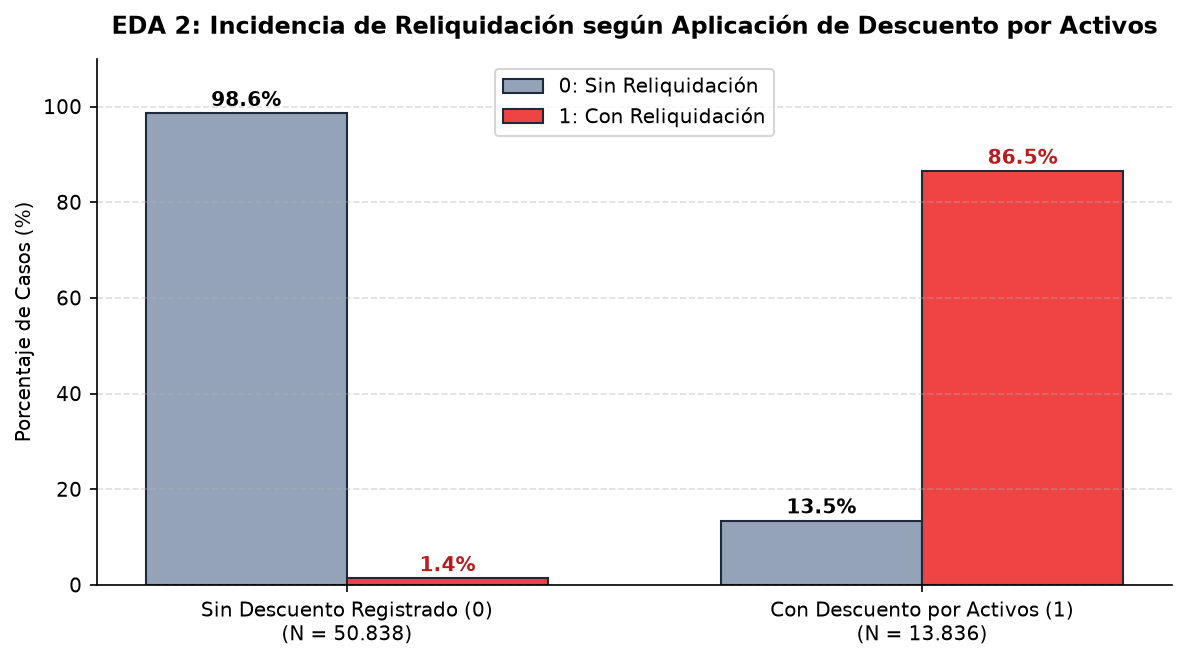

In [6]:
# Figura 3 (EDA 2): Incidencia de Reliquidación según Aplicación de Descuento por Activos
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)
ct = pd.crosstab(df["CasoConDescuento_0_1"], df["CasoConReliquidacion_0_1"], normalize="index") * 100
x = np.arange(2)
w = 0.35
b1 = ax.bar(x - w/2, ct[0], width=w, label="0: Sin Reliquidación", color="#94A3B8", edgecolor="#1E293B")
b2 = ax.bar(x + w/2, ct[1], width=w, label="1: Con Reliquidación", color="#EF4444", edgecolor="#1E293B")
for b in b1:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1.5, f"{b.get_height():.1f}%", ha="center", fontweight="bold", fontsize=9.5)
for b in b2:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1.5, f"{b.get_height():.1f}%", ha="center", fontweight="bold", fontsize=9.5, color="#B91C1C")
ax.set_xticks(x)
ax.set_xticklabels(["Sin Descuento Registrado (0)\n(N = 50.838)", "Con Descuento por Activos (1)\n(N = 13.836)"])
ax.set_ylim(0, 110)
ax.set_ylabel("Porcentaje de Casos (%)")
ax.set_title("EDA 2: Incidencia de Reliquidación según Aplicación de Descuento por Activos", fontweight="bold", pad=12)
ax.legend(loc="upper center")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig("figuras/fig3_eda_descuento_vs_reliquidacion.png", dpi=180)
plt.show()

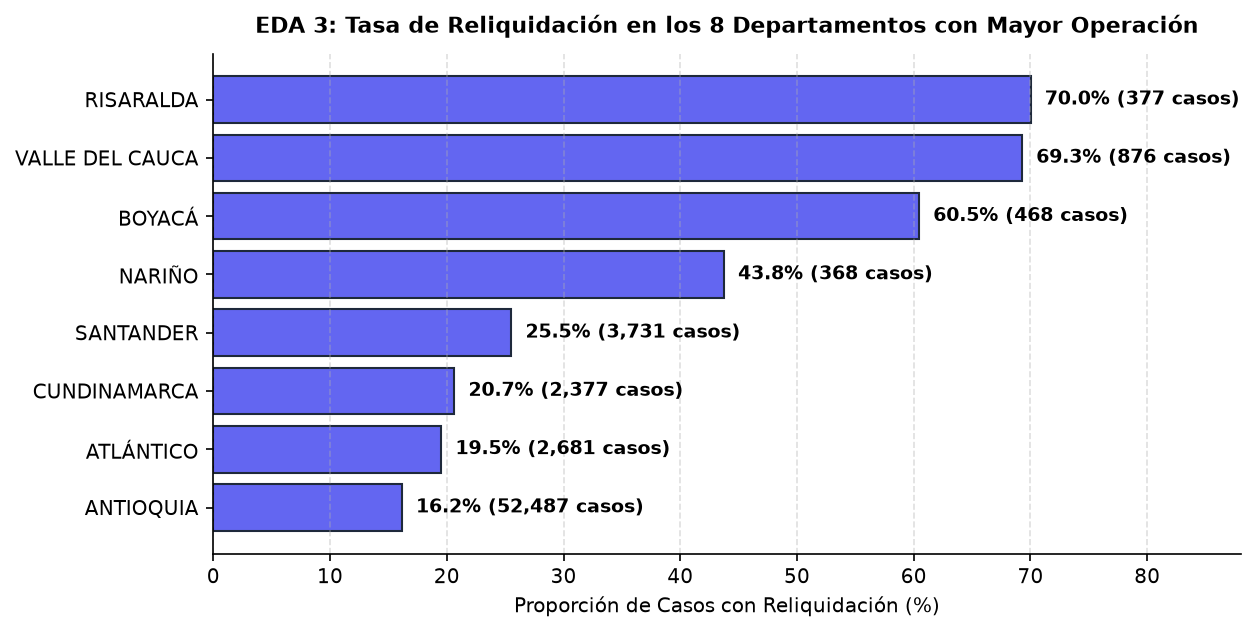

In [7]:
# Figura 4 (EDA 3): Tasa de Reliquidación en los 8 Departamentos con Mayor Operación
for k, v in [("ATL", "ATLÁNTICO"), ("BOYAC", "BOYACÁ"), ("NARI", "NARIÑO")]:
    df.loc[df["NombreDepartamento"].str.startswith(k, na=False), "NombreDepartamento"] = v

df_dep = df.groupby("NombreDepartamento").agg(
    casos=("CasoKey", "count"),
    tasa=("CasoConReliquidacion_0_1", lambda s: s.mean()*100)
).reset_index().sort_values("casos", ascending=False).head(8).sort_values("tasa", ascending=True)

fig, ax = plt.subplots(figsize=(8.5, 4.3), dpi=150)
bars = ax.barh(df_dep["NombreDepartamento"], df_dep["tasa"], color="#6366F1", edgecolor="#1E293B")
for bar, (_, row) in zip(bars, df_dep.iterrows()):
    ax.text(bar.get_width() + 1.2, bar.get_y() + bar.get_height()/2,
            f"{row['tasa']:.1f}% ({int(row['casos']):,} casos)", va="center", fontsize=9, fontweight="bold")
ax.set_xlim(0, 88)
ax.set_xlabel("Proporción de Casos con Reliquidación (%)")
ax.set_title("EDA 3: Tasa de Reliquidación en los 8 Departamentos con Mayor Operación", fontweight="bold", fontsize=10.5, pad=10)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig("figuras/fig4_eda_departamento.png", dpi=180)
plt.show()

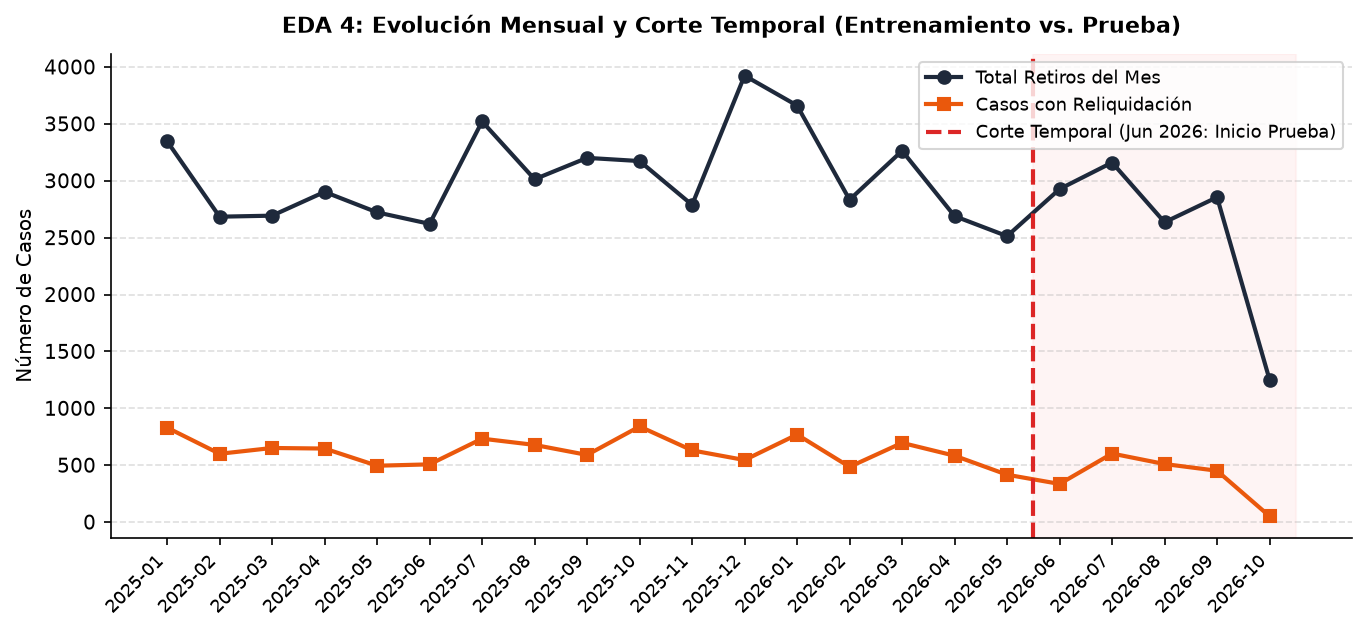

In [8]:
# Figura 5 (EDA 4): Evolución Mensual y Corte Temporal (Entrenamiento vs. Prueba)
df["PeriodoMes"] = df["AnioReporte"] * 100 + df["MesReporte"]
df_ev = df[df["PeriodoMes"] >= 202501].groupby("PeriodoMes").agg(
    casos=("CasoKey", "count"),
    reliq=("CasoConReliquidacion_0_1", "sum")
).reset_index().sort_values("PeriodoMes")
df_ev["Etiqueta"] = df_ev["PeriodoMes"].astype(str).str[:4] + "-" + df_ev["PeriodoMes"].astype(str).str[4:]

fig, ax = plt.subplots(figsize=(9.2, 4.3), dpi=150)
ax.plot(df_ev["Etiqueta"], df_ev["casos"], marker="o", color="#1E293B", linewidth=2, label="Total Retiros del Mes")
ax.plot(df_ev["Etiqueta"], df_ev["reliq"], marker="s", color="#EA580C", linewidth=2, label="Casos con Reliquidación")
split_idx = list(df_ev["PeriodoMes"]).index(202606) - 0.5
ax.axvline(split_idx, color="#DC2626", linestyle="--", linewidth=2, label="Corte Temporal (Jun 2026: Inicio Prueba)")
ax.axvspan(split_idx, len(df_ev)-0.5, color="#FEE2E2", alpha=0.35)
ax.set_xticks(range(len(df_ev)))
ax.set_xticklabels(df_ev["Etiqueta"], rotation=45, ha="right", fontsize=8.5)
ax.set_ylabel("Número de Casos")
ax.set_title("EDA 4: Evolución Mensual y Corte Temporal (Entrenamiento vs. Prueba)", fontweight="bold", fontsize=10.5, pad=10)
ax.legend(loc="upper right", fontsize=8.5)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig("figuras/fig5_eda_evolucion_temporal.png", dpi=180)
plt.show()

## 3. Preparación de los Datos: Limpieza, Variables Derivadas y División Temporal
1. **Tratamiento de nulos y atípicos (Sección 3.1):**
   - `Transportadora`: `32.201` registros con guion `'-'` se recodifican como `'Sin Transportadora'` y `3.022` registros `'NULL'` como `'No Registrada'`.
   - `DiasReporteLiquidacion`: `480` registros nulos (pendientes de liquidar) se imputan con la mediana general (`2,0` días), y `971` registros con valores atípicos (`911` negativos por desfase de captura y `60` superiores a 60 días) se acotan al rango operativo `[0, 60]` días.
2. **Variables derivadas conocidas antes del cierre/predicción (Sección 3.2):**
   - `TieneTransportadoraAsignada_0_1`: identifica si el contrato tiene una transportadora activa asignada para recolección física.
   - `TasaReliqTranspMesAnterior` y `VolumenRetirosTranspMesAnterior`: tasa de reliquidación y carga operativa de esa misma transportadora en el mes inmediatamente anterior ($t-1$).
   - `TasaReliqMuniMesAnterior`: proporción histórica de reliquidación en el municipio durante el mes anterior ($t-1$).
   - `LogValorDescontadoCOP`: transformación logarítmica $\ln(1 + \text{ValorDescontadoCOP})$ para estabilizar la asimetría monetaria.
3. **División estrictamente temporal (Sección 3.3):**
   - **Entrenamiento:** Octubre 2024 – Mayo 2026 (`51.846` casos, `80,17 %`).
   - **Prueba:** Junio 2026 – Octubre 2026 (`12.828` casos, `19,83 %`).

In [9]:
# 3.1 Limpieza de nulos y atípicos
df["Compania_Limpia"] = df["Compania"].replace({"NULL": "No Especificada", "": "No Especificada"}).fillna("No Especificada")
df["MotivoRetiro_Limpio"] = df["MotivoRetiro"].fillna("Voluntario")

mediana_dias = float(df["DiasReporteLiquidacion"].median())
df["DiasReporteLiquidacion_Limpio"] = df["DiasReporteLiquidacion"].fillna(mediana_dias).clip(lower=0, upper=60)

# 3.2 Creación de variables derivadas sin fuga temporal (usando rezago t-1)
transportadoras_activas = ["BSL", "RABLAN", "LC", "OCLOCK", "Presencial", "MOVESCOL", "PAKKI"]
df["TieneTransportadoraAsignada_0_1"] = df["Transportadora_Limpia"].isin(transportadoras_activas).astype(int)

periodos_ordenados = sorted(df["PeriodoMes"].unique())
mapa_siguiente_mes = {periodos_ordenados[i]: periodos_ordenados[i+1] for i in range(len(periodos_ordenados)-1)}

mensual_transp = df.groupby(["PeriodoMes", "Transportadora_Limpia"]).agg(
    VolumenRetirosTranspMesAnterior=("CasoKey", "count"),
    TasaReliqTranspMesAnterior=("CasoConReliquidacion_0_1", "mean")
).reset_index()
mensual_transp["PeriodoMes"] = mensual_transp["PeriodoMes"].map(mapa_siguiente_mes)
mensual_transp = mensual_transp.dropna(subset=["PeriodoMes"])

mensual_muni = df.groupby(["PeriodoMes", "CodigoMunicipio"]).agg(
    TasaReliqMuniMesAnterior=("CasoConReliquidacion_0_1", "mean")
).reset_index()
mensual_muni["PeriodoMes"] = mensual_muni["PeriodoMes"].map(mapa_siguiente_mes)
mensual_muni = mensual_muni.dropna(subset=["PeriodoMes"])

df = df.merge(mensual_transp, on=["PeriodoMes", "Transportadora_Limpia"], how="left")
df = df.merge(mensual_muni, on=["PeriodoMes", "CodigoMunicipio"], how="left")

df["VolumenRetirosTranspMesAnterior"] = df["VolumenRetirosTranspMesAnterior"].fillna(0)
df["TasaReliqTranspMesAnterior"] = df["TasaReliqTranspMesAnterior"].fillna(df["CasoConReliquidacion_0_1"].mean())
df["TasaReliqMuniMesAnterior"] = df["TasaReliqMuniMesAnterior"].fillna(df["CasoConReliquidacion_0_1"].mean())
df["LogValorDescontadoCOP"] = np.log1p(df["ValorDescontadoCOP"].clip(lower=0))

# Codificación One-Hot de variables categóricas
top_companias = df["Compania_Limpia"].value_counts().head(12).index.tolist()
df["Compania_Agrupada"] = df["Compania_Limpia"].where(df["Compania_Limpia"].isin(top_companias), "Otras Compañías")

top_deptos = df["NombreDepartamento"].value_counts().head(8).index.tolist()
df["Depto_Agrupado"] = df["NombreDepartamento"].where(df["NombreDepartamento"].isin(top_deptos), "Otros Departamentos")

categorical_cols = ["Transportadora_Limpia", "MotivoRetiro_Limpio", "Compania_Agrupada", "Depto_Agrupado", "EstadoDevolucion"]
numeric_cols = [
    "MesReporte", "TrimestreReporte", "ReporteFinDeSemana",
    "DiasReporteLiquidacion_Limpio", "LiquidadoEn10Dias_0_1",
    "CantidadActivosPendientes", "CasoConDescuento_0_1", "LogValorDescontadoCOP",
    "TieneTransportadoraAsignada_0_1", "VolumenRetirosTranspMesAnterior",
    "TasaReliqTranspMesAnterior", "TasaReliqMuniMesAnterior"
]

df_encoded = pd.get_dummies(df[numeric_cols + categorical_cols], columns=categorical_cols, drop_first=False, dtype=int)

# 3.3 División Temporal: Entrenamiento (Oct 2024 - May 2026) vs Prueba (Jun 2026 - Oct 2026)
train_mask = df["PeriodoMes"] <= 202605
test_mask = df["PeriodoMes"] >= 202606

X_train, y_train = df_encoded.loc[train_mask].copy(), df.loc[train_mask, "CasoConReliquidacion_0_1"].astype(int)
X_test, y_test = df_encoded.loc[test_mask].copy(), df.loc[test_mask, "CasoConReliquidacion_0_1"].astype(int)

print(f"Conjunto de Entrenamiento (Oct 2024 - May 2026): {len(X_train):,} filas | Casos con reliquidación: {y_train.sum():,} ({y_train.mean()*100:.2f}%)")
print(f"Conjunto de Prueba        (Jun 2026 - Oct 2026): {len(X_test):,} filas | Casos con reliquidación: {y_test.sum():,} ({y_test.mean()*100:.2f}%)")
print(f"Total de variables de entrada (tras One-Hot Encoding): {X_train.shape[1]}")

Conjunto de Entrenamiento (Oct 2024 - May 2026): 51,846 filas | Casos con reliquidación: 10,726 (20.69%)
Conjunto de Prueba        (Jun 2026 - Oct 2026): 12,828 filas | Casos con reliquidación: 1,949 (15.19%)
Total de variables de entrada (tras One-Hot Encoding): 59


## 4. Modelado y 5. Evaluación sobre el Conjunto de Prueba (Figuras 6 y 7)
Se entrenan dos algoritmos de clasificación con el **mismo conjunto de entrenamiento (`51.846` registros)** y las **mismas `59` variables de entrada**:
1. **Regresión Logística (`LogisticRegression`):** modelo lineal probabilístico interpretable con regularización $L_2$ (`C=0.05, max_iter=500, random_state=42`).
2. **Bosque Aleatorio (`RandomForestClassifier`):** ensamble no lineal de árboles de decisión (`n_estimators=200, max_depth=12, min_samples_split=10, min_samples_leaf=4, class_weight='balanced_subsample', random_state=42`).

In [10]:
# Escalamiento estándar de columnas numéricas para la Regresión Logística
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

# Entrenamiento Algoritmo 1: Regresión Logística
model_lr = LogisticRegression(C=0.05, max_iter=500, random_state=42)
model_lr.fit(X_train_scaled, y_train)
y_pred_lr = model_lr.predict(X_test_scaled)
y_prob_lr = model_lr.predict_proba(X_test_scaled)[:, 1]

# Entrenamiento Algoritmo 2: Bosque Aleatorio (Random Forest)
model_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=4,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)
model_rf.fit(X_train, y_train)
y_pred_rf = model_rf.predict(X_test)
y_prob_rf = model_rf.predict_proba(X_test)[:, 1]

# Tabla comparativa de métricas en el conjunto de prueba
resultados = []
for nombre, y_p, y_pr in [("Regresión Logística", y_pred_lr, y_prob_lr), ("Bosque Aleatorio (Random Forest)", y_pred_rf, y_prob_rf)]:
    tn, fp, fn, tp = confusion_matrix(y_test, y_p).ravel()
    resultados.append({
        "Algoritmo": nombre,
        "VN (Normales Acertados)": int(tn),
        "FP (Falsas Alarmas)": int(fp),
        "FN (Reliq. No Detectadas)": int(fn),
        "VP (Reliq. Detectadas)": int(tp),
        "Exactitud (Accuracy %)": round(accuracy_score(y_test, y_p)*100, 2),
        "Precisión (%)": round(precision_score(y_test, y_p)*100, 2),
        "Sensibilidad / Recall (%)": round(recall_score(y_test, y_p)*100, 2),
        "F1-Score (%)": round(f1_score(y_test, y_p)*100, 2),
        "ROC-AUC (%)": round(roc_auc_score(y_test, y_pr)*100, 2)
    })

df_res = pd.DataFrame(resultados)
display(df_res)

,Algoritmo,VN (Normales Acertados),FP (Falsas Alarmas),FN (Reliq. No Detectadas),VP (Reliq. Detectadas),Exactitud (Accuracy %),Precisión (%),Sensibilidad / Recall (%),F1-Score (%),ROC-AUC (%)
0,Regresión Logística,9946,933,25,1924,92.53,67.34,98.72,80.07,96.92
1,Bosque Aleatorio (Random Forest),9932,947,13,1936,92.52,67.15,99.33,80.13,97.89


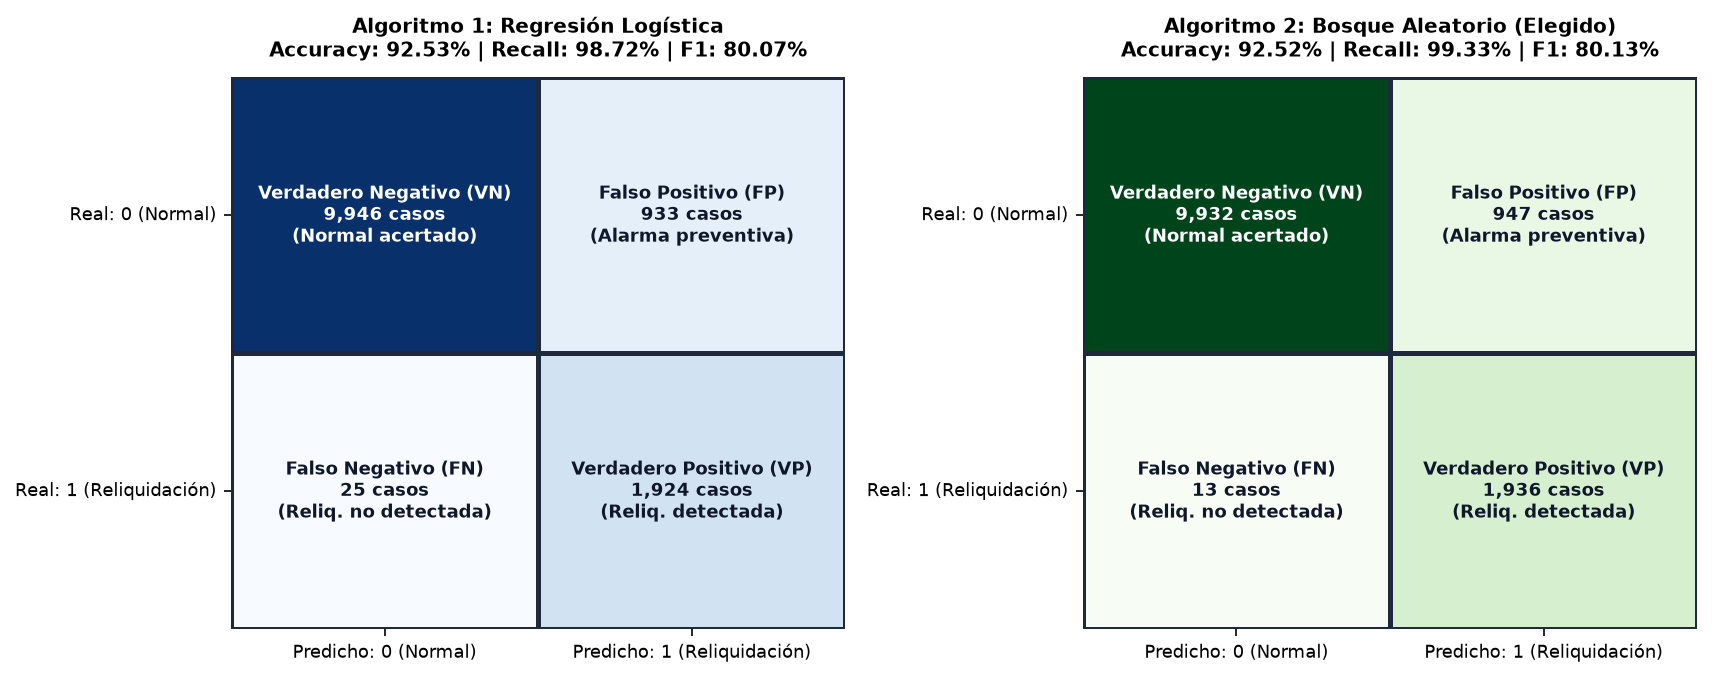

In [11]:
# Figura 6 (Sección 5.1): Matrices de Confusión de Regresión Logística vs. Bosque Aleatorio
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), dpi=150)
for ax, res, title, cmap in [
    (axes[0], resultados[0], "Algoritmo 1: Regresión Logística", "Blues"),
    (axes[1], resultados[1], "Algoritmo 2: Bosque Aleatorio (Elegido)", "Greens")
]:
    cm_arr = np.array([[res["VN (Normales Acertados)"], res["FP (Falsas Alarmas)"]],
                       [res["FN (Reliq. No Detectadas)"], res["VP (Reliq. Detectadas)"]]])
    sns.heatmap(cm_arr, annot=False, cmap=cmap, cbar=False, ax=ax, linewidths=1.5, linecolor="#1E293B")
    cell_labels = [
        [f"Verdadero Negativo (VN)\n{res['VN (Normales Acertados)']:,} casos\n(Normal acertado)",
         f"Falso Positivo (FP)\n{res['FP (Falsas Alarmas)']:,} casos\n(Alarma preventiva)"],
        [f"Falso Negativo (FN)\n{res['FN (Reliq. No Detectadas)']:,} casos\n(Reliq. no detectada)",
         f"Verdadero Positivo (VP)\n{res['VP (Reliq. Detectadas)']:,} casos\n(Reliq. detectada)"]
    ]
    for i in range(2):
        for j in range(2):
            val = cm_arr[i, j]
            text_color = "white" if val > (cm_arr.max() * 0.45) else "#0F172A"
            ax.text(j + 0.5, i + 0.5, cell_labels[i][j], ha="center", va="center",
                    color=text_color, fontweight="bold", fontsize=8.5)
    ax.set_xticklabels(["Predicho: 0 (Normal)", "Predicho: 1 (Reliquidación)"], fontsize=8.5)
    ax.set_yticklabels(["Real: 0 (Normal)", "Real: 1 (Reliquidación)"], rotation=0, fontsize=8.5)
    ax.set_title(f"{title}\nAccuracy: {res['Exactitud (Accuracy %)']:.2f}% | Recall: {res['Sensibilidad / Recall %)']:.2f}% | F1: {res['F1-Score %)']:.2f}%"
                 if "Sensibilidad / Recall %)" in res else
                 f"{title}\nAccuracy: {res['Exactitud (Accuracy %)']:.2f}% | Recall: {res['Sensibilidad / Recall (%)']:.2f}% | F1: {res['F1-Score (%)']:.2f}%",
                 fontweight="bold", fontsize=9.5, pad=10)
plt.subplots_adjust(wspace=0.35)
plt.tight_layout()
plt.savefig("figuras/fig6_matrices_confusion.png", dpi=180)
plt.show()

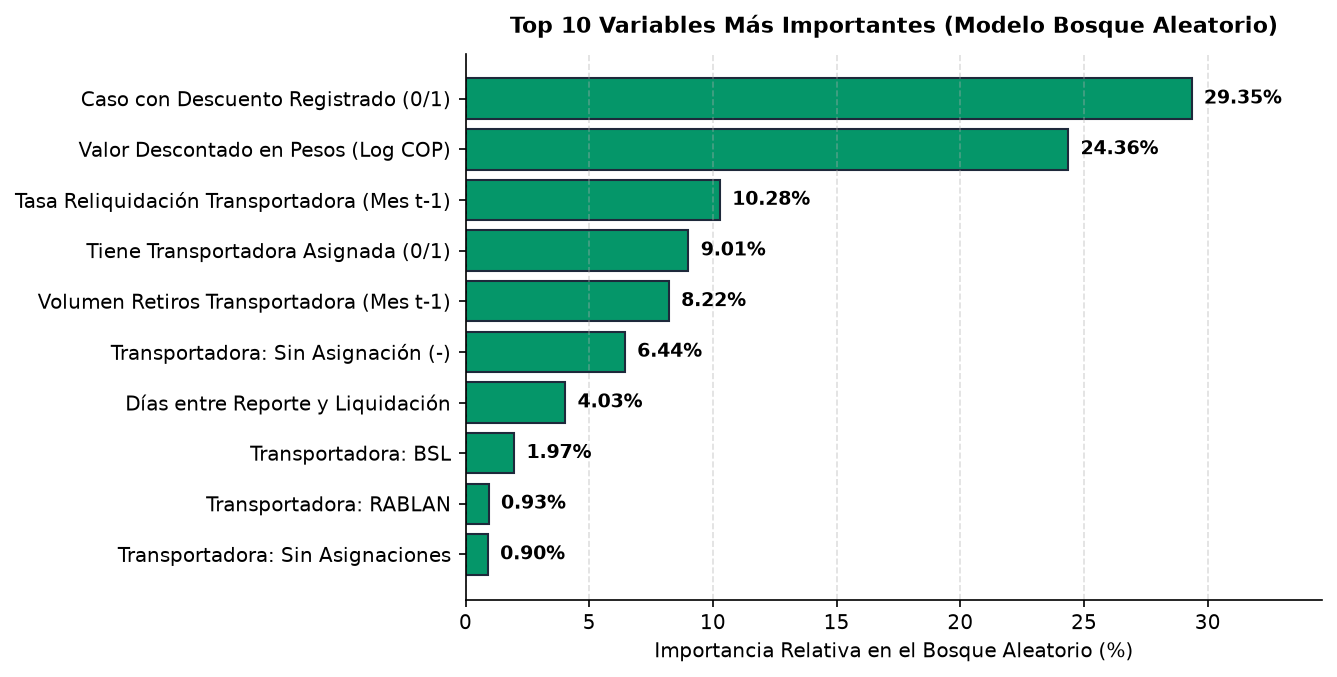

In [12]:
# Figura 7 (Sección 5.3): Gráfico de las 10 Variables Más Importantes en el Bosque Aleatorio
pretty_names = {
    "CasoConDescuento_0_1": "Caso con Descuento Registrado (0/1)",
    "LogValorDescontadoCOP": "Valor Descontado en Pesos (Log COP)",
    "TasaReliqTranspMesAnterior": "Tasa Reliquidación Transportadora (Mes t-1)",
    "TieneTransportadoraAsignada_0_1": "Tiene Transportadora Asignada (0/1)",
    "VolumenRetirosTranspMesAnterior": "Volumen Retiros Transportadora (Mes t-1)",
    "Transportadora_Limpia_Sin Transportadora": "Transportadora: Sin Asignación (-)",
    "DiasReporteLiquidacion_Limpio": "Días entre Reporte y Liquidación",
    "Transportadora_Limpia_BSL": "Transportadora: BSL",
    "Transportadora_Limpia_RABLAN": "Transportadora: RABLAN",
    "Transportadora_Limpia_Sin Asignaciones": "Transportadora: Sin Asignaciones"
}

importances = pd.Series(model_rf.feature_importances_ * 100, index=X_train.columns).sort_values(ascending=False).head(10)
top10_series = importances[::-1]
labels_imp = [pretty_names.get(col, col) for col in top10_series.index]
vals_imp = top10_series.values

fig, ax = plt.subplots(figsize=(9.0, 4.6), dpi=150)
bars = ax.barh(labels_imp, vals_imp, color="#059669", edgecolor="#1E293B")
for bar, v in zip(bars, vals_imp):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, f"{v:.2f}%", va="center", fontweight="bold", fontsize=9)
ax.set_xlim(0, max(vals_imp) * 1.18)
ax.set_xlabel("Importancia Relativa en el Bosque Aleatorio (%)")
ax.set_title("Top 10 Variables Más Importantes (Modelo Bosque Aleatorio)", fontweight="bold", fontsize=10.5, pad=10)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig("figuras/fig7_importancia_variables.png", dpi=180)
plt.show()

## 6. Despliegue de Predicciones en el Data Warehouse (`bi_entrega2.pred_reliquidacion`)
Se verifica que las **64.674 predicciones** generadas por el modelo elegido (`RandomForestClassifier`) estén almacenadas en la tabla `pred_reliquidacion` del Data Warehouse con sus llaves foráneas hacia `dim_tiempo`, `dim_ubicacion`, `dim_contrato` y `dim_estado`, lista para alimentar la **Página 3 de Power BI**.

In [13]:
# Consulta de verificación sobre la tabla desplegada pred_reliquidacion en MySQL
verif_sql = '''
SELECT
    ConjuntoDatos,
    COUNT(*) AS TotalCasos,
    SUM(RealReliquidacion_0_1) AS CasosRealesReliq,
    SUM(PrediccionReliquidacion_0_1) AS CasosPredichosReliq,
    ROUND(AVG(ProbabilidadReliquidacion)*100, 2) AS ProbabilidadPromedioPct
FROM pred_reliquidacion
GROUP BY ConjuntoDatos;
'''
df_verif = pd.read_sql(verif_sql, engine)
display(df_verif)

,ConjuntoDatos,TotalCasos,CasosRealesReliq,CasosPredichosReliq,ProbabilidadPromedioPct
0,ENTRENAMIENTO,51846,10726.0,10987.0,24.79
1,PRUEBA,12828,1949.0,2883.0,22.37
